# 5. Tables and targets

Everything `terminator` computes at runtime comes out of a small directory of
`.npz` lookup tables plus a frozen target registry. Nothing heavier than numpy
is imported. This notebook opens the tables directly, so you can see exactly
what the runtime is reading — and where its caveats are recorded.

```
index.json                              # version, planets, scenarios
models/<planet-slug>__<scenario>.npz    # wavelength_um, transit_depth, meta
star/<planet-slug>.npz                  # wavelength_um, f_lambda, meta
noise/<planet-slug>.npz                 # wavelength_um, depth_err_1transit
ld/<planet-slug>.npz                    # wavelength_um, u1, u2, meta
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo

print("terminator", lazuli_exo.__file__)

terminator /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/terminator/src/lazuli_exo/__init__.py


## Locating the tables

`resolve_tables_dir()` looks in three places, in order: an explicit
`tables_dir=` argument, then the `LAZULI_EXO_TABLES` environment variable,
then the `data/tables/` shipped alongside the package source.

In [2]:
from pathlib import Path
from lazuli_exo import tables

tdir = tables.resolve_tables_dir(None)
print(f"tables dir: {tdir}\n")

for sub in ["models", "star", "noise", "ld"]:
    files = sorted((tdir / sub).glob("*.npz"))
    mb = sum(f.stat().st_size for f in files) / 1e6
    print(f"  {sub:8s} {len(files):3d} files  {mb:6.2f} MB")

total = sum(f.stat().st_size for f in tdir.rglob("*")
            if f.is_file()) / 1e6
print(f"\n  {'total':8s} {total:16.2f} MB")

tables dir: /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/terminator/src/lazuli_exo/data/tables

  models    70 files   14.08 MB
  star      15 files   11.20 MB
  noise     14 files    0.13 MB
  ld        14 files    0.03 MB

  total               50.70 MB


## The index

`index.json` is the catalogue. It carries a schema `version`, and
`load_index()` refuses a mismatch rather than silently misreading tables.

In [3]:
index = tables.load_index(tdir)

print(f"schema version: {index['version']} "
      f"(supported: {tables.SCHEMA_VERSION})")
print(f"planets:        {len(index['planets'])}\n")

entry = index["planets"]["WASP-39 b"]
print("index['planets']['WASP-39 b']:")
for k, v in entry.items():
    print(f"  {k:12s} {v}")

schema version: 2 (supported: 2)
planets:        14

index['planets']['WASP-39 b']:
  has_ld       True
  has_noise    True
  scenarios    ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  slug         wasp-39-b


The index is regenerated from what is actually on disk by
`tables.rebuild_index()`, which every precompute script calls when it
finishes — so the catalogue cannot drift from the files.

In [4]:
missing = []
for name, e in index["planets"].items():
    for s in e["scenarios"]:
        p = tdir / "models" / f"{e['slug']}__{s}.npz"
        if not p.exists():
            missing.append(str(p))
    for sub, flag in [("noise", "has_noise"), ("ld", "has_ld")]:
        if e.get(flag) and not (tdir / sub / f"{e['slug']}.npz").exists():
            missing.append(str(tdir / sub / f"{e['slug']}.npz"))

print(f"indexed files missing from disk: {missing or 'none'}")
assert not missing

indexed files missing from disk: none


## The four table types

Each loader returns its arrays plus the `meta` dict that records how the table
was produced.

In [5]:
PLANET = "WASP-39 b"

wl_m, depth_m, meta_m = tables.load_model(tdir, PLANET, "clear")
wl_s, flam_s, meta_s = tables.load_star(tdir, PLANET)
wl_n, err_n, meta_n = tables.load_noise(tdir, PLANET)
wl_l, u1_l, u2_l, meta_l = tables.load_ld(tdir, PLANET)

print(f"{'table':8s}{'samples':>9s}{'wavelength range (um)':>26s}")
for lab, w in [("model", wl_m), ("star", wl_s),
               ("noise", wl_n), ("ld", wl_l)]:
    print(f"{lab:8s}{w.size:9d}{w.min():14.4f} - {w.max():.4f}")

table     samples     wavelength range (um)
model       16650        0.3500 - 1.8500
star        16650        0.3500 - 1.8500
noise         525        0.4000 - 1.6993
ld             48        0.4061 - 1.6746


The model grid is built at R = 10 000 over 0.35–1.85 µm (margin around the
0.40–1.70 µm IFS bandpass), while the noise table is sampled at the
instrument's own channel spacing. That difference is why `observe()` bins both
onto a common constant-R grid rather than interpolating one onto the other.

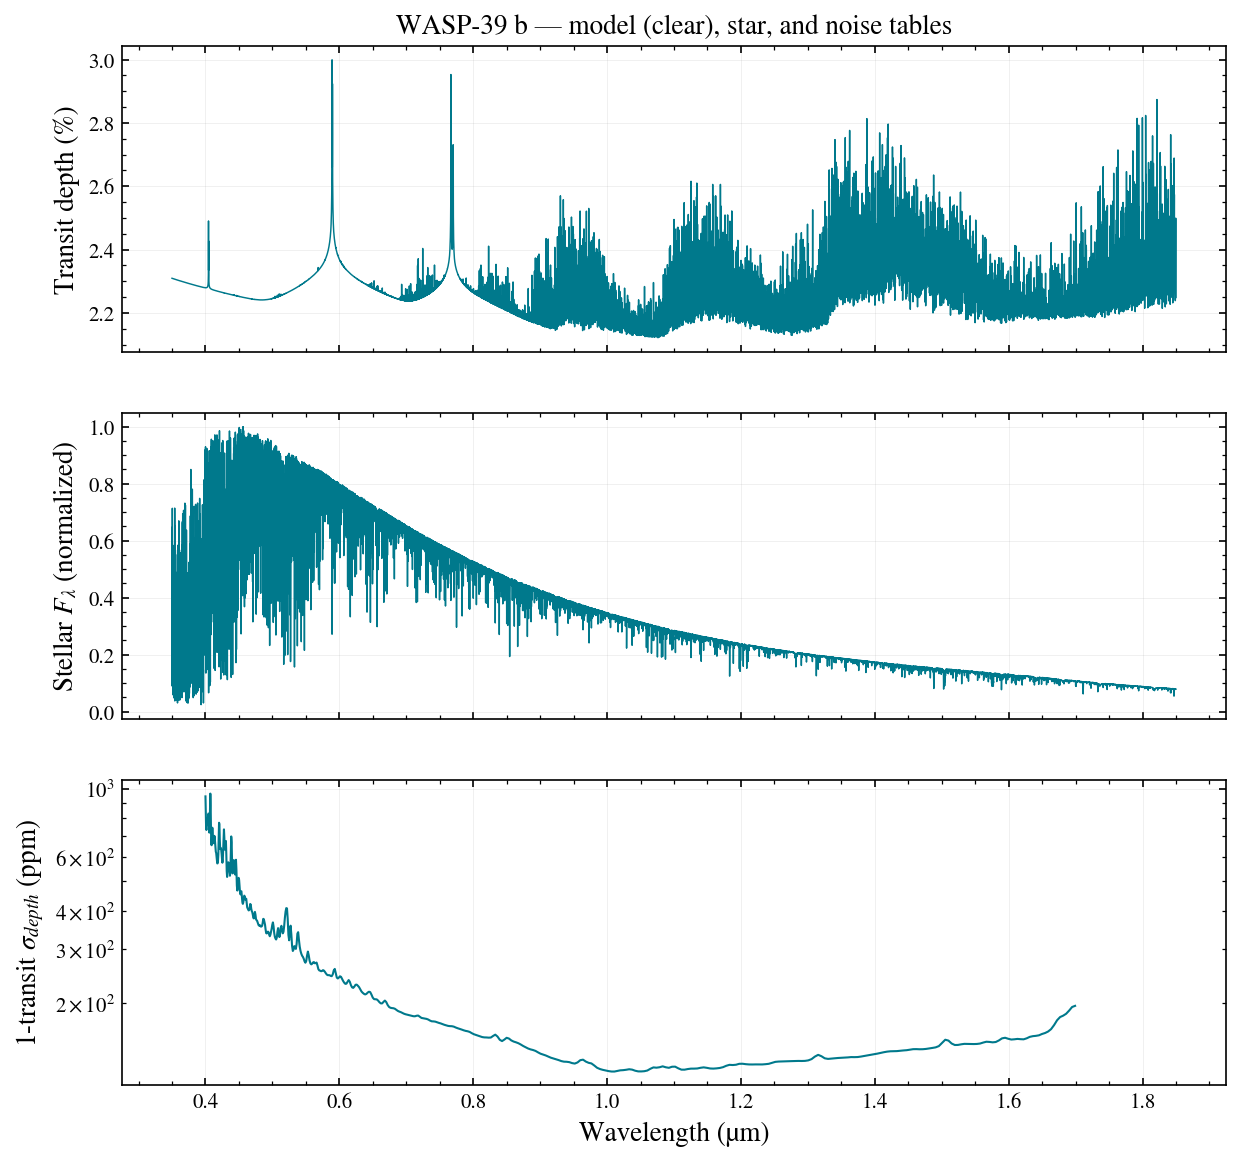

star grid: phoenix, T_eff = 5485.0 K, units = POSEIDON F_star (W/m^2/m)


In [6]:
fig, axes = plt.subplots(3, 1, figsize=(9.5, 9), sharex=True)

axes[0].plot(wl_m, depth_m * 100.0, lw=0.7)
axes[0].set_ylabel("Transit depth (%)")
axes[0].set_title(f"{PLANET} — model (clear), star, and noise tables")

axes[1].plot(wl_s, flam_s / flam_s.max(), lw=0.7)
axes[1].set_ylabel("Stellar $F_\\lambda$ (normalized)")

axes[2].plot(wl_n, err_n * 1e6, lw=1.0)
axes[2].set_ylabel("1-transit $\\sigma_{depth}$ (ppm)")
axes[2].set_yscale("log")
axes[2].set_xlabel("Wavelength (µm)")

plt.show()

print(f"star grid: {meta_s['stellar_grid']}, "
      f"T_eff = {meta_s['T_eff_K']} K, units = {meta_s['units']}")

## What the noise table records

The noise `meta` is the provenance of every error bar `terminator` reports —
the instrument, the normalization band, the readout mode actually used, and
the assumption the depth uncertainty rests on.

In [7]:
for k, v in meta_n.items():
    print(f"  {k:20s} {v}")

  generator            make_noise_tables.py
  created              2026-10-04
  J_mag                10.663
  norm_band            2massj
  stellar_grid         phoenix
  slicersim_version    1.0.0
  instrument           lazuli_cbe
  band                 J
  sncosmo_band         2massj
  mag_input            10.663
  mag_system           vega
  vega_ab_offset       0.8993018775290533
  mag_ab               11.562301877529054
  t14_s                10091.52
  t_obs_s              90.56
  default_nmd          [16, 8, 0]
  nmd_used             [4, 8, 0]
  nramps               1
  nsaturated_detpx     0
  fully_desaturated    True
  trimmed_channels     0
  assumption           equal out-of-transit baseline; SNR ~ sqrt(t); readout tuned to remove point-source saturation
  planet               WASP-39 b


## Noise vs. host brightness

Single-transit depth precision is driven mostly by how bright the host is.
Plotting the median against the registry's J magnitude shows the expected
photon-limited trend, with the sub-Neptune and terrestrial hosts at the
faint end.

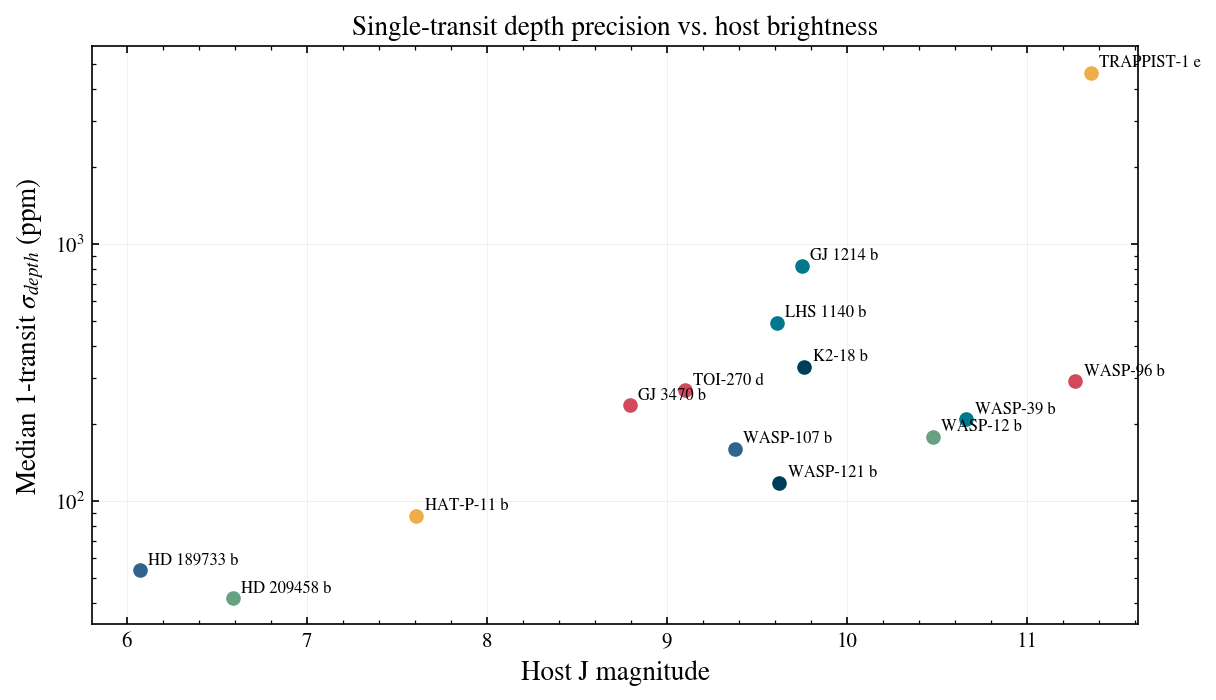

In [8]:
from lazuli_exo.targets import get_target

rows = []
for p in lazuli_exo.list_planets():
    _, e, _ = tables.load_noise(tdir, p)
    rows.append((p, get_target(p)["J_mag"], np.median(e)))

fig, ax = plt.subplots(figsize=(9, 5))
for p, j, e in rows:
    ax.plot(j, e * 1e6, "o", ms=6)
    ax.annotate(p, (j, e * 1e6), fontsize=8,
                xytext=(4, 3), textcoords="offset points")

ax.set_yscale("log")
ax.set_xlabel("Host J magnitude")
ax.set_ylabel("Median 1-transit $\\sigma_{depth}$ (ppm)")
ax.set_title("Single-transit depth precision vs. host brightness")
plt.show()

## The target registry

`lazuli_exo.targets` is a frozen snapshot of the NASA Exoplanet Archive
`PSCompPars` table (plus a few overrides), generated by
`precompute/freeze_targets.py`. It is a plain dict — no network access at
runtime, and no dependency on the archive being up.

In [9]:
fields = ["T_eq_K", "R_p_RJ", "R_s_RSun", "T_eff_K", "J_mag",
          "period_d", "a_over_rs", "inc_deg", "depth"]

print(f"{'planet':14s}" + "".join(f"{f:>11s}" for f in fields))
for p in lazuli_exo.list_planets():
    t = get_target(p)
    print(f"{p:14s}" + "".join(f"{t[f]:11.4g}" for f in fields))

planet             T_eq_K     R_p_RJ   R_s_RSun    T_eff_K      J_mag   period_d  a_over_rs    inc_deg      depth
GJ 1214 b             567     0.2438     0.2162       3101       9.75       1.58      14.97      88.98    0.01343
GJ 3470 b           593.5     0.4077      0.547       3600      8.794      3.337      13.98      89.13    0.00584
HAT-P-11 b            838      0.389      0.683       4653      7.608      4.888      16.72      89.03   0.003363
HD 189733 b          1209       1.13       0.75       5052      6.073      2.219       8.84      85.71    0.02413
HD 209458 b          1459       1.39       1.19       6091      6.591      3.525       8.81      86.71    0.01461
K2-18 b               284     0.2114      0.411       3457      9.763      32.94      83.83      89.58   0.002889
LHS 1140 b            226     0.1543     0.2159       3096      9.612      24.74      95.34      89.86   0.005461
TOI-270 d             383     0.1784       0.38       3506      9.099      11.38      41

In [10]:
t = get_target("K2-18 b")
print("full registry entry for K2-18 b:\n")
for k, v in sorted(t.items()):
    print(f"  {k:12s} {v}")

full registry entry for K2-18 b:

  J_mag        9.763
  M_p_MJ       0.02806532
  Met_star     0.12
  R_p_RJ       0.21143724
  R_s_RSun     0.411
  T_eff_K      3457.0
  T_eq_K       284.0
  a_over_rs    83.83
  depth        0.0028890624999999997
  ecc          0.2
  inc_deg      89.5785
  log_g_star   4.7864
  name         K2-18 b
  period_d     32.939623
  provenance   NEA PSCompPars
  slug         k2-18-b
  t14_s        9655.199999999999
  w_deg        -5.7


Unknown names fail loudly, listing what is available — the same behaviour as
`load_model` for an unknown planet or scenario.

In [11]:
for call, label in [
    (lambda: get_target("Kepler-999 b"), "get_target"),
    (lambda: tables.load_model(tdir, "Kepler-999 b", "clear"), "load_model"),
    (lambda: tables.load_model(tdir, "WASP-39 b", "stormy"), "scenario"),
]:
    try:
        call()
    except KeyError as exc:
        print(f"{label:12s} KeyError: {str(exc)[:88]}...")
    else:
        raise AssertionError(f"{label} should have raised")

get_target   KeyError: "Unknown target 'Kepler-999 b'. Available: ['GJ 1214 b', 'GJ 3470 b', 'HAT-P-11 b', 'HD ...
load_model   KeyError: "Unknown planet 'Kepler-999 b'. Available: ['GJ 1214 b', 'GJ 3470 b', 'HAT-P-11 b', 'HD ...
scenario     KeyError: "Unknown scenario 'stormy' for 'WASP-39 b'. Available: ['clear', 'cloudy', 'flat', 'hazy...


## The saturation caveat

Three bright hosts could not be fully de-saturated even at slicersim's minimal
MACC configuration. Rather than silently ignoring that, the residual pixel
count is recorded in the noise table and `observe()` raises a `UserWarning`.

<div class="alert alert-warning">

For these three targets the uncertainties are **unvalidated** — saturation can
bias extraction weights, nonlinearity, and wavelength dependence in either
direction. Treat their forecasts as indicative only.

</div>

In [12]:
print(f"{'planet':14s}{'desaturated':>13s}{'saturated px':>14s}"
      f"{'nmd used':>10s}")
flagged = []
for p in lazuli_exo.list_planets():
    _, _, m = tables.load_noise(tdir, p)
    ok = m.get("fully_desaturated")
    if ok is False:
        flagged.append(p)
    print(f"{p:14s}{str(ok):>13s}{m.get('nsaturated_detpx', 0):14d}"
          f"{str(m.get('nmd_used')):>10s}")

print(f"\nflagged: {flagged}")

planet          desaturated  saturated px  nmd used
GJ 1214 b              True             0 [2, 8, 0]
GJ 3470 b              True             0 [2, 4, 0]
HAT-P-11 b             True             0 [2, 1, 0]
HD 189733 b           False          1540 [2, 1, 0]
HD 209458 b           False           784 [2, 1, 0]
K2-18 b                True             0 [2, 8, 0]
LHS 1140 b             True             0 [2, 8, 0]
TOI-270 d              True             0 [2, 4, 0]
TRAPPIST-1 e           True             0 [8, 8, 0]
WASP-107 b             True             0 [2, 8, 0]
WASP-12 b              True             0 [2, 8, 0]
WASP-121 b             True             0 [2, 8, 0]


WASP-39 b              True             0 [4, 8, 0]
WASP-96 b              True             0 [4, 8, 0]

flagged: ['HD 189733 b', 'HD 209458 b']


In [13]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    lazuli_exo.observe(flagged[0], scenario="clear", n_transits=1)

for w in caught:
    print(f"{w.category.__name__}: {w.message}")

assert caught and caught[0].category is UserWarning

## Pointing at a different tables directory

For a deployment that does not ship `data/tables/` — a wheel install, or a web
dyno — set `LAZULI_EXO_TABLES`, or pass `tables_dir=` per call. Both take
precedence over the packaged default, in that order.

In [14]:
import os

print(f"default (package-relative): {tables.resolve_tables_dir(None)}")
print(f"explicit argument:          "
      f"{tables.resolve_tables_dir('/some/other/tables')}")

os.environ["LAZULI_EXO_TABLES"] = "/from/the/environment"
print(f"from $LAZULI_EXO_TABLES:    {tables.resolve_tables_dir(None)}")
del os.environ["LAZULI_EXO_TABLES"]

# an explicit argument still wins over the environment variable
os.environ["LAZULI_EXO_TABLES"] = "/from/the/environment"
print(f"argument beats env:         "
      f"{tables.resolve_tables_dir('/explicit/wins')}")
del os.environ["LAZULI_EXO_TABLES"]

# observe() takes the same argument
obs = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1,
                         tables_dir=tdir)
print(f"\nobs.meta['tables_dir']:     {obs.meta['tables_dir']}")

default (package-relative): /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/terminator/src/lazuli_exo/data/tables
explicit argument:          /some/other/tables
from $LAZULI_EXO_TABLES:    /from/the/environment
argument beats env:         /explicit/wins

obs.meta['tables_dir']:     /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/terminator/src/lazuli_exo/data/tables


## Summary

- Four table types under one directory, catalogued by a version-stamped
  `index.json` that `rebuild_index()` regenerates from disk.
- Every table carries a `meta` dict recording how it was produced — model
  settings, stellar grid, readout mode, LD grid point.
- The registry (`lazuli_exo.targets`) is a frozen NEA snapshot; no network at
  runtime.
- The caveats live in the data, not just the docs: `T_clamped` on cold
  planets, `fully_desaturated` on bright hosts (which also raises a
  `UserWarning`).
- `tables_dir=` beats `$LAZULI_EXO_TABLES` beats the packaged default.

That is the whole runtime. For the physics and statistics caveats behind these
numbers, see the [user guide](../user_guide/index.rst).